# 추가 실험 · 적분점을 압축층에 모으면 위치와 기울기가 함께 개선되는가?

시간 의존 벡터 Burgers, 점성 0.02, 왼쪽 1·오른쪽 0, no-slip 벽. 시험 차수 8(45개), 시간 Gauss 8점, tanh 32×3, Adam 3000 및 L-BFGS 최대 1500회를 사용한다. 각 조건은 같은 초기화 시드 2026–2030으로 새로 학습한다.

## 실험 설계 · 압축층을 찾고 그 주변에 점을 놓는 방법

전역 조건은 원호 진행 좌표에 32·64·128개, 폭 방향에 40개의 Gauss–Legendre 점을 놓는다. 집중 조건에서는 각 학습 시각에 P3 시간 상태를 선형 보간하고 중심선 접선 속도가 0.5를 아래로 지나는 위치를 구한다. 그 위치 ±0.30의 띠에 진행 방향 24점, 앞뒤에 각각 20점을 둔다. 띠 폭은 0.60으로 관 길이의 약 9.5%다. 여기에 전체 점의 37.5%를 놓는다. 각 진행 방향 점에 폭 방향 40점을 결합해 총 2560점 중 960점이 띠 안에 놓인다. 각 구간의 Gauss 가중치에 구간 길이와 원호 면적 Jacobian을 적용한다. 경계 각 변 128점, 초기조건은 초기 점프의 좌우 각각 64×40점이다. 즉 집중은 점의 개수로 구현하고, 각 점이 대표하는 면적은 구간별 가중치로 보정했다. P3 위치를 미리 알아야 하는 설계다. 아래 그림에서 주황점은 집중 띠, 파란점은 그 바깥이며 각 행은 하나의 학습 시각이다.

### 좌표 변환과 Gauss 가중치

원호 길이 좌표는 $0\le s\le L=2\pi$, 폭 좌표는 $-1/2\le\eta\le1/2$다. 반지름 $R=4$, 각도 $\theta=3\pi/4-s/R$로 두면 물리점은 $(R+\eta)(\cos\theta,\sin\theta)$이고 면적 요소는 $(1+\eta/R)\,ds\,d\eta$다.

진행 구간 $[a,b]$의 $n$점 Gauss–Legendre 절점 $\xi_i$는 $P_n(\xi_i)=0$의 근이다. 표준 가중치는 $w_i=2/[(1-\xi_i^2)P_n'(\xi_i)^2]$다. 폭 방향에는 40점 규칙 $(\zeta_j,v_j)$를 쓴다. 길이·폭 절점과 물리 면적 가중치는

$$s_i=a+\frac{b-a}{2}(1+\xi_i),\qquad \eta_j=\frac{\zeta_j}{2},\qquad W_{ij}=w_i v_j\frac{b-a}{4}\left(1+\frac{\eta_j}{R}\right).$$

| 배치 | 진행 구간과 구간별 절점 수 | 폭 방향 | 시각당 공간점 |
|---|---|---:|---:|
| 전역 | $[0,L]$에 32 / 64 / 128개 | 40 | 1,280 / 2,560 / 5,120 |
| 집중 | 아래 세 구간에 20 / 24 / 20개 | 40 | 2,560 |

시간은 $t_k=(1+\tau_k)/2$인 8점 Gauss 규칙이다. 각 $t_k$에서 인접 P3 저장 시각의 속도를 시간 선형 보간한다. 중심선 2,001점에서 접선 속도 $q(s)=\boldsymbol U_h(s,0,t_k)\cdot(\sin\theta,-\cos\theta)$를 평가한다. 유일한 하향 통과 $q_i\ge0.5>q_{i+1}$에서

$$c_k=s_i+(s_{i+1}-s_i)\frac{0.5-q_i}{q_{i+1}-q_i}.$$

집중 규칙은 $[0,c_k-0.30]$, $[c_k-0.30,c_k+0.30]$, $[c_k+0.30,L]$에 위 식을 각각 적용한다. 중심 띠는 관 길이의 9.55%에 해당하며 960점(37.5%)을 받는다. 예컨대 첫 시각 $t\approx0.01986$의 띠는 $[2.8513,3.4513]$이다. 각 시각의 $W_{ij}$ 합은 전체 면적 $2\pi$다. 시드는 신경망 초기화를 바꾸며 네 배치 모두 시험 차수 8, 경계 각 변 128점, 초기 점프 좌우 각 $64\times40$점을 사용한다.

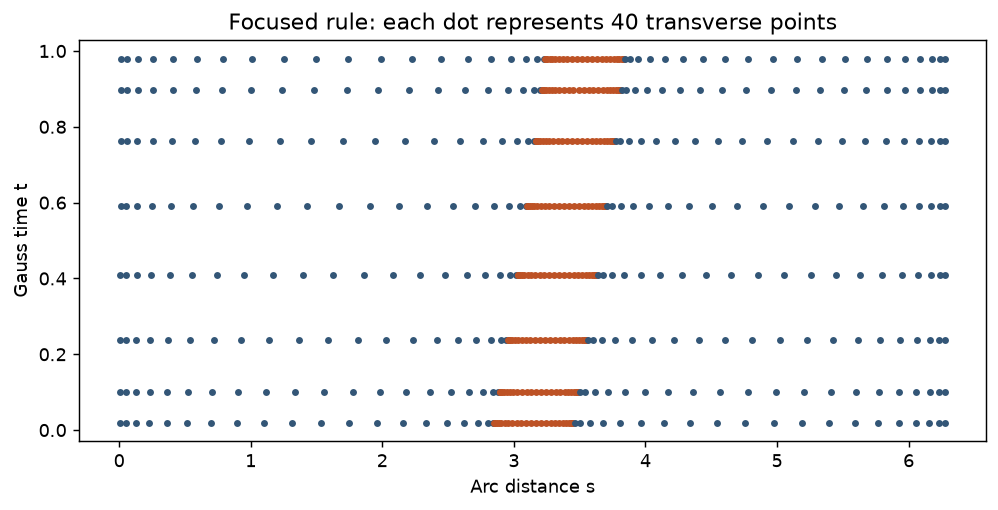

In [ ]:
from IPython.display import Image,display
display(Image(filename='p8_figure_1.png'))

독립 약형 잔차는 공통 시험 차수 30·공간 160×56·시간 256점에서 계산한 쌍대노름 제곱이다. 강형 RMS와 P3 대비 해 오차는 일곱 시각에서 평가한다. H1은 공간 기울기의 상대 seminorm, 최대오차는 유한 표본의 절대 최대다. 위치 오차는 최종 시각의 유일한 중심선 하향 통과를 사용한다.

## 전체 10개와 시드 2034 제외 9개 비교

**벡터해의 절대 RMS 오차**에서 해는 두 속도 성분으로 이루어진 $\boldsymbol U=(u,v)$다. VPINN과 P3의 같은 지점·시각에서 두 성분 차이의 제곱합을 구한다.
$$E_{\rm RMS}=\left[\frac{1}{0.99\,|\Omega|}\int_{0.01}^{1}\!\int_\Omega \big((u_\theta-u_h)^2+(v_\theta-v_h)^2\big)\,dx\,dt\right]^{1/2}.$$
공간은 P3 요소 적분, 시간은 일곱 평가 시각의 사다리꼴 적분이다. 값은 속도와 같은 단위다. 반면 **강형 PDE 잔차 RMS**는 예측해를 방정식에 대입해 남는 잔차의 크기를 나타낸다.

**점성 압축층 위치 $s$ ($t=1$)** 는 관 중심선에서 VPINN이 예측한 층의 대표 좌표다. 왼쪽 유입구에서 오른쪽으로 잰 원호 거리 $s$에 대해 접선 속도 $\boldsymbol U_\theta(s,0,1)\cdot\boldsymbol e_s$가 0.5를 하향 통과하는 위치를 선형 보간한다. 통과가 유일할 때만 기록한다. **점성 압축층 위치 절대오차**는 같은 기준으로 구한 P3 위치와의 거리 $|s_\theta-s_h|$다. 위치 자체는 어느 쪽에 층이 있는지를, 위치 오차는 얼마나 맞췄는지를 보여준다.

### 벡터해의 표본 $L^\infty$ 절대오차

각 평가 시각에서 VPINN 속도와 P3 속도의 **벡터 차이의 길이**를 계산한 뒤 가장 큰 값을 찾았다. 시각은 $T_Q=\{0.01,0.02,0.05,0.1,0.2,0.5,1\}$, 공간 표본 $Q$는 P3 요소 적분점과 원호 좌표 $161\times49$ 격자의 합집합이다.
$$E_{\infty,Q}=\max_{t\in T_Q}\max_{x\in Q}\sqrt{(u_\theta-u_h)^2+(v_\theta-v_h)^2}.$$
한 시드의 값은 **관측한 최악 지점의 속도 오차**다. 각 시드에서 먼저 최대를 구한 뒤 시드 평균과 표본 SD를 냈다. 연속 시공간의 supremum은 더 클 수 있다.

**점 수를 늘리면 두 집합 모두에서 평균 해 오차가 줄었다.** 전역 1,280 → 2,560 → 5,120점의 상대 L2는 전체에서 18.16 → 13.25 → 10.31%, 제외 후 17.75 → 12.21 → 10.42%였다. 상대 H1 seminorm과 표본 최대오차도 두 집합 모두 같은 순서로 감소했다. 강형·약형 잔차는 점 수에 따라 단조 감소하지 않았다.

| 배치 | 전체 10개 · 평균 ± SD | 2034 제외 9개 · 평균 ± SD |
|---|---:|---:|
| 전역 1280 | 2.066 ± 1.3 (10/10) | 2.185 ± 1.32 (9/9) |
| 전역 2560 | 1.309 ± 0.561 (10/10) | 1.35 ± 0.579 (9/9) |
| 전역 5120 | 1.008 ± 0.526 (10/10) | 1.02 ± 0.556 (9/9) |
| 집중 2560 | 1.214 ± 0.901 (10/10) | 1.285 ± 0.925 (9/9) |

**전역 5,120점에서 관측한 최대 속도 오차 평균이 두 집합 모두 가장 작았다.** 같은 2,560점에서 집중 배치의 평균은 조금 낮아졌지만 시드 간 산포는 커졌다. 아래 시드별 그림의 최대오차 패널에서 확인할 수 있다.

제외 기준은 각 시드의 점성 압축층 위치 절대오차 (t=1) 차이(집중−전역 2,560점)가 유효 쌍 중앙값에서 떨어진 거리다. 2034의 차이는 −0.3918, 중앙값은 −0.0746, 거리는 0.3172였다. 동일한 시드를 모든 배치에서 제외했다. 두 집합은 9개 시드를 공유한다. 표의 ±는 표본 표준편차이고 괄호는 유효 수다.

### 해 오차와 압축층 위치 · 시드별 결과

가는 선 하나가 같은 시드의 네 배치 결과다. 주황색 점선은 2034다. 각 배치 옆 검정 마름모와 파란 사각형은 각각 전체 10개와 2034 제외 9개의 평균이며, 세로 막대는 표본 표준편차(±1 SD)다. 아래 숫자 지도에서 개별 점의 값을 확인할 수 있다.

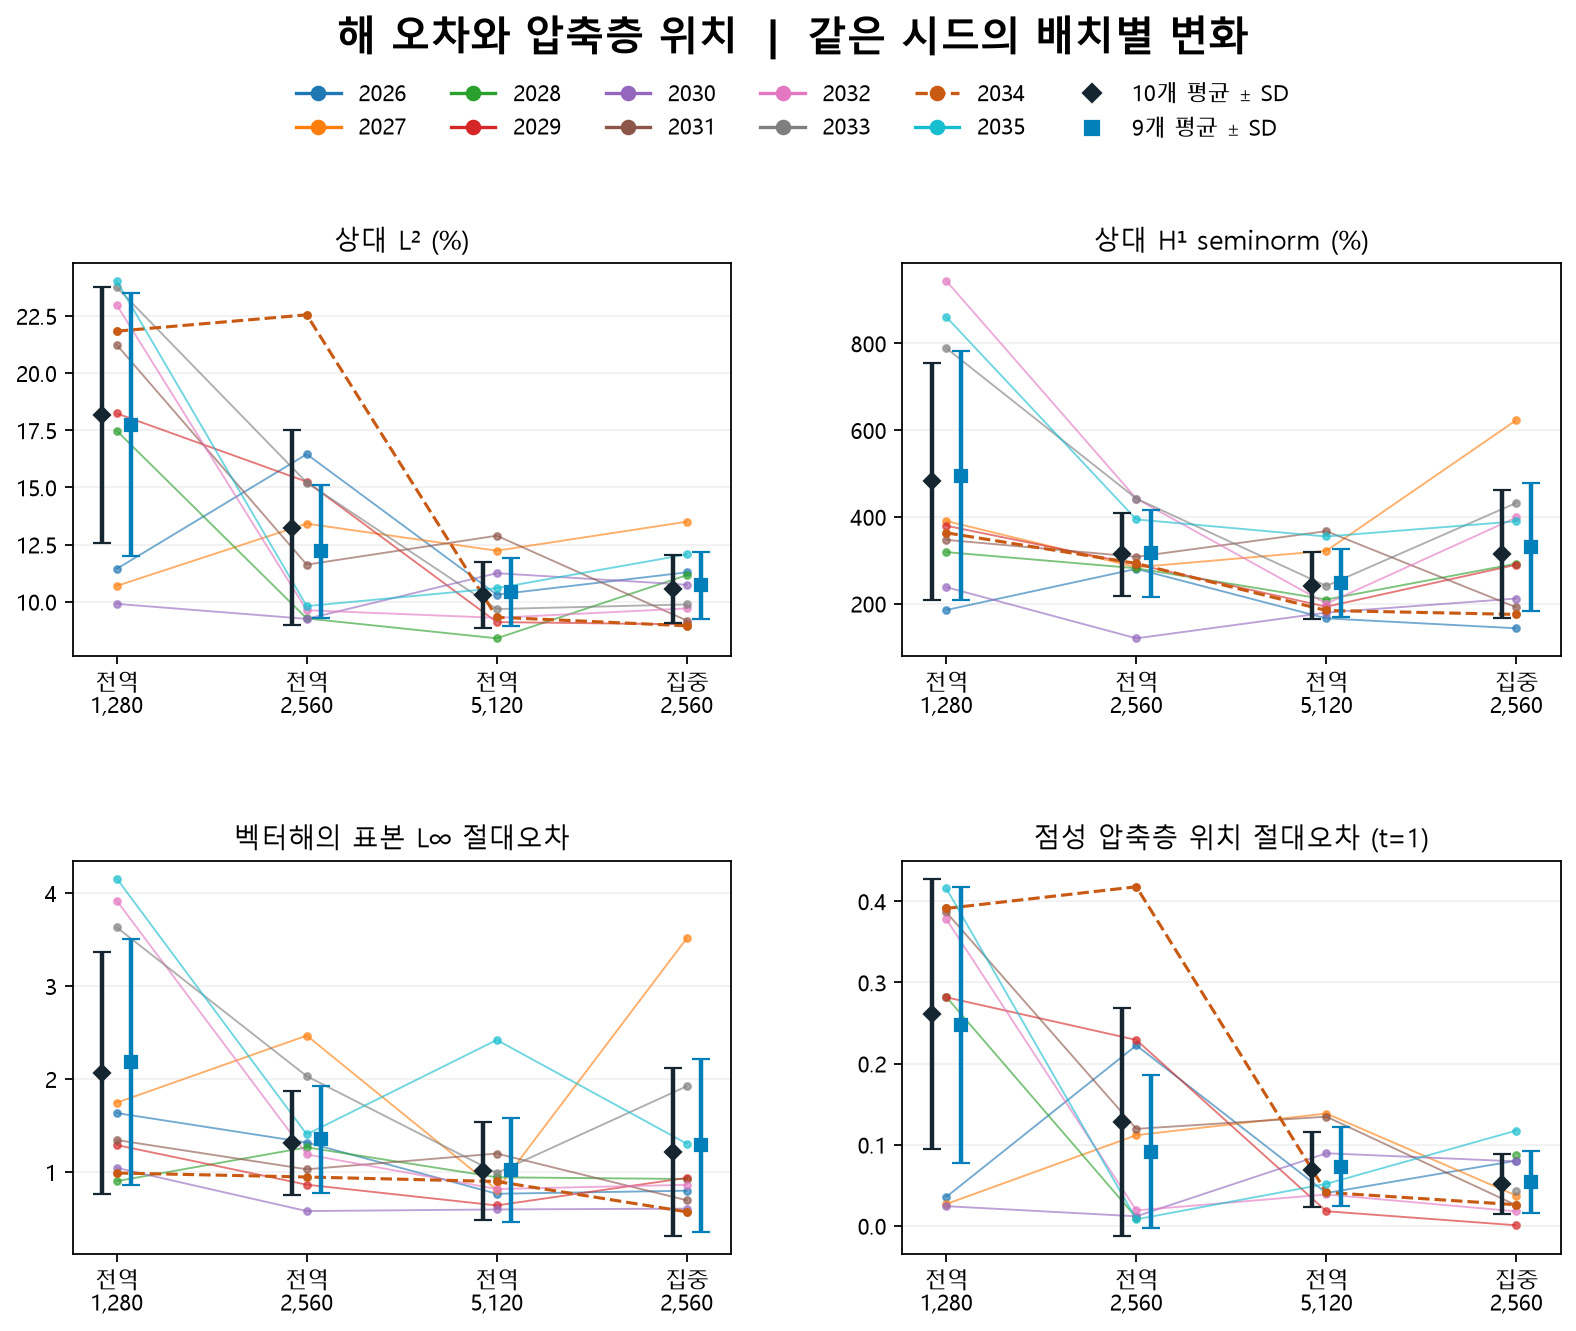

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_profiles_1.png'))

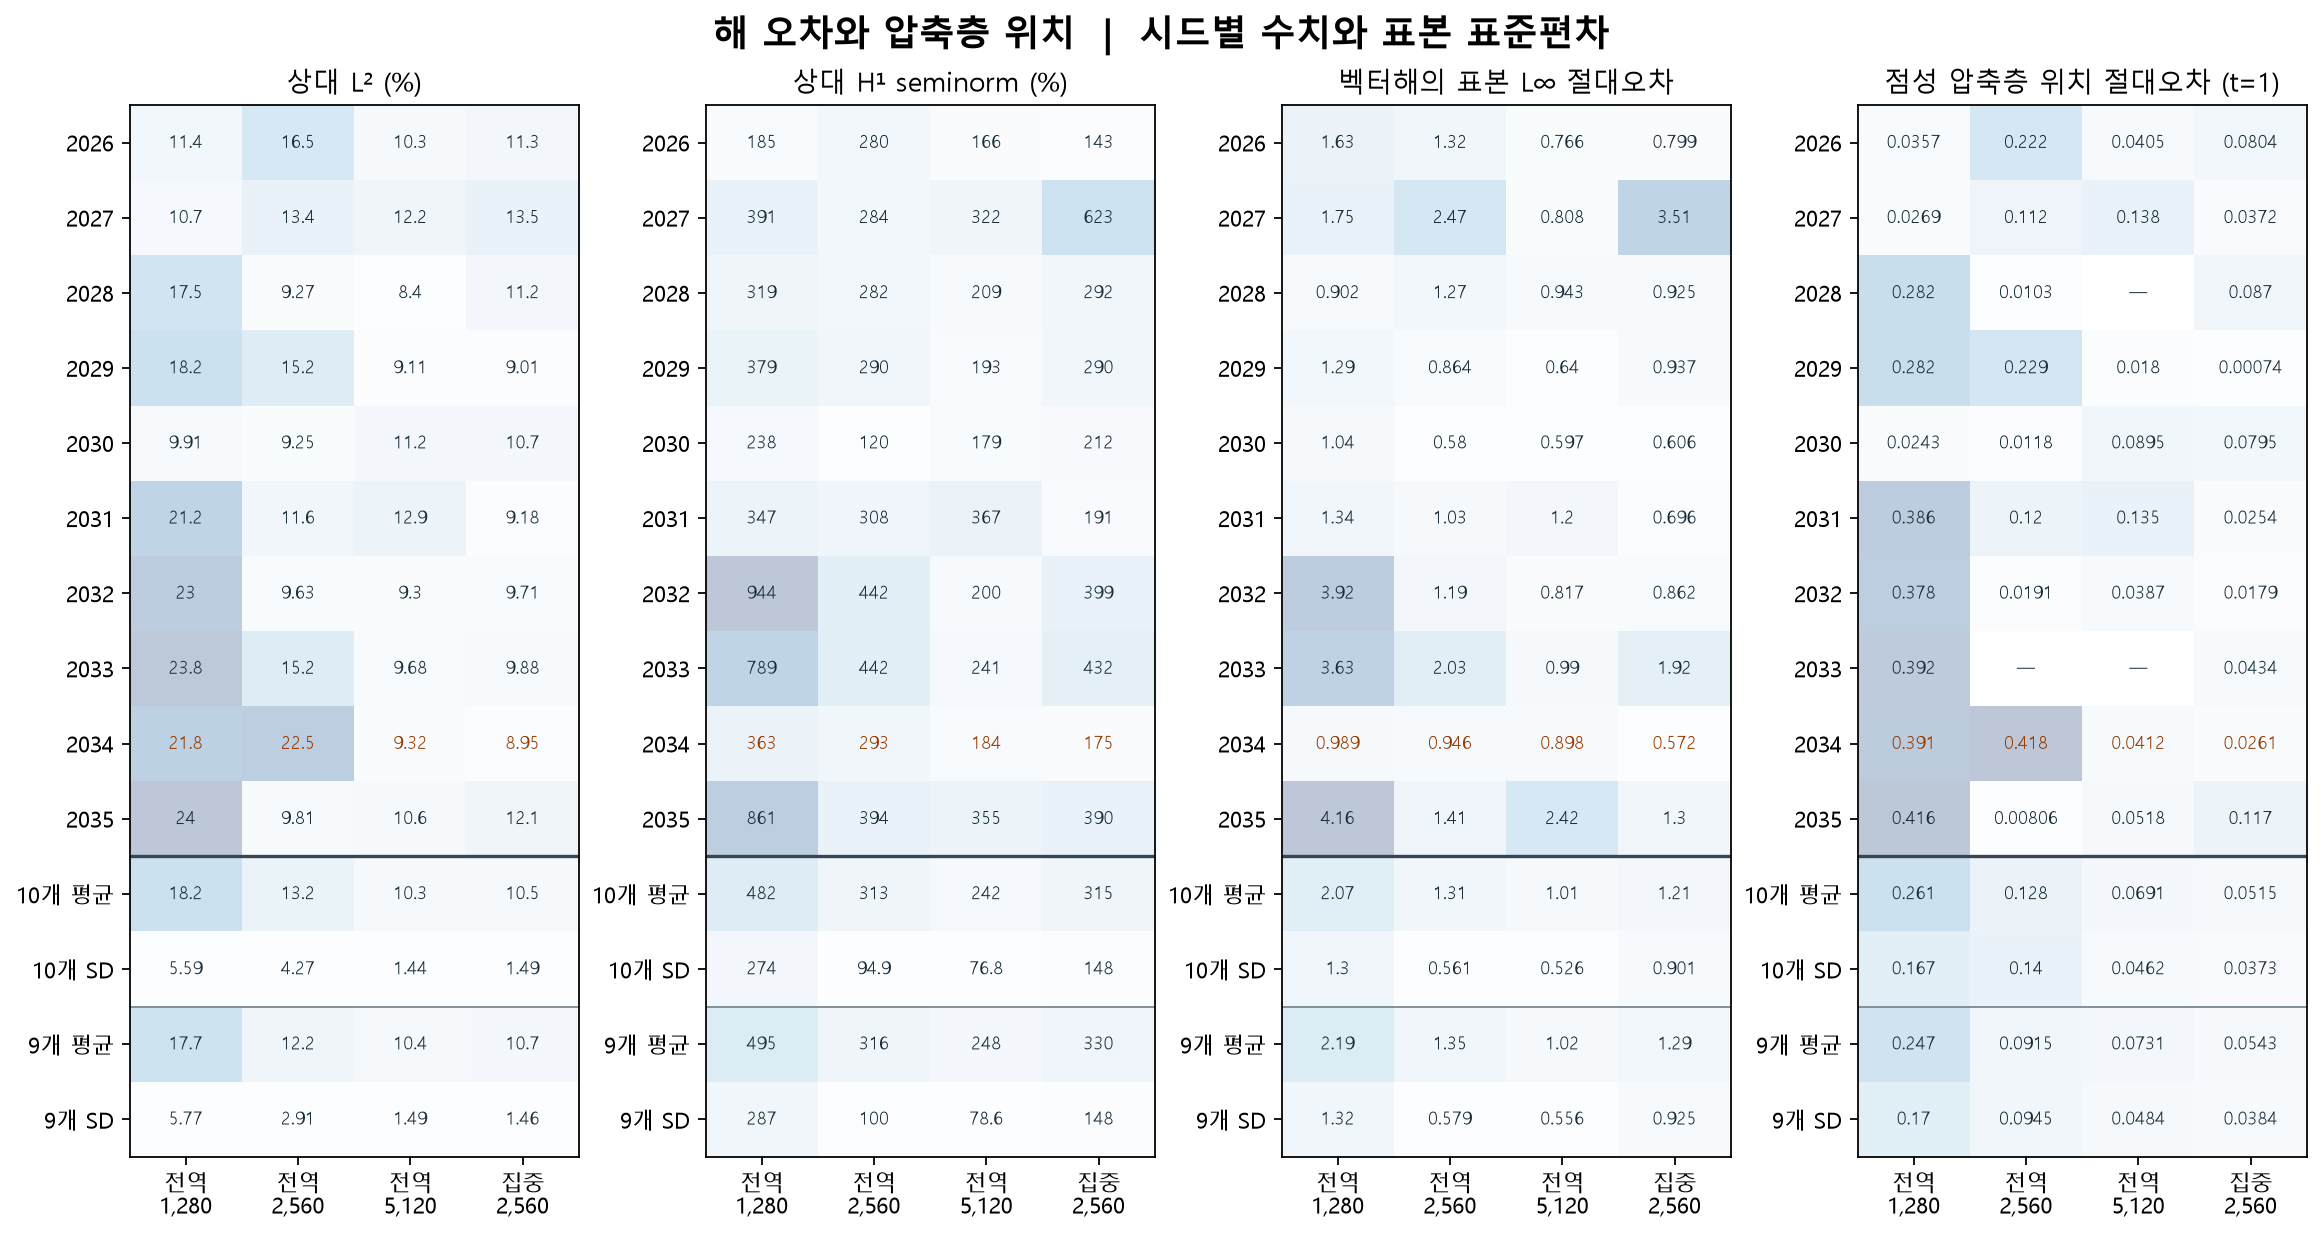

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_values_1.png'))

각 열은 한 배치다. 아래 네 줄은 평균과 표본 SD이며, —는 유일한 하향 통과를 정할 수 없어 해당 지표를 집계에서 제외한 경우다. 색 농도는 각 지표 안에서만 비교한다.

### 잔차와 계산 비용 · 시드별 결과

가는 선 하나가 같은 시드의 네 배치 결과다. 주황색 점선은 2034다. 각 배치 옆 검정 마름모와 파란 사각형은 각각 전체 10개와 2034 제외 9개의 평균이며, 세로 막대는 표본 표준편차(±1 SD)다. 아래 숫자 지도에서 개별 점의 값을 확인할 수 있다.

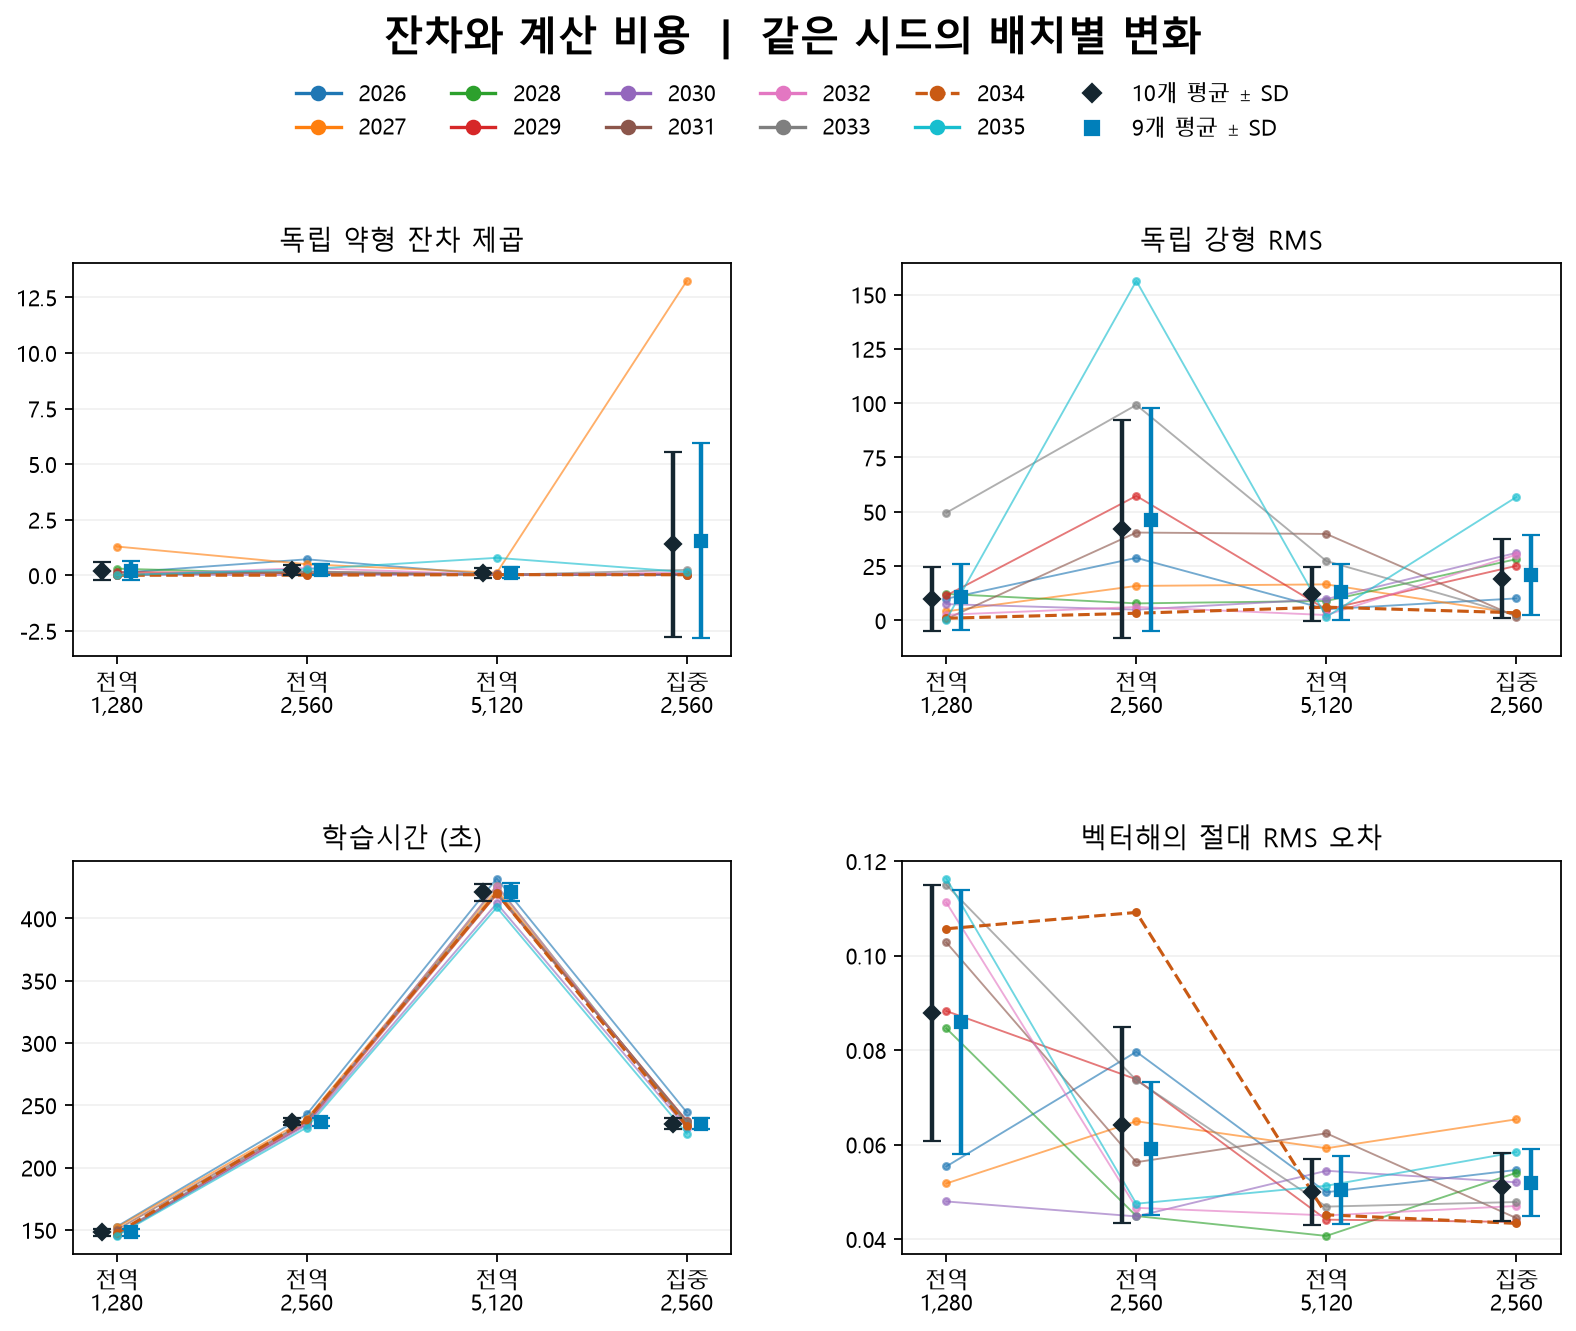

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_profiles_2.png'))

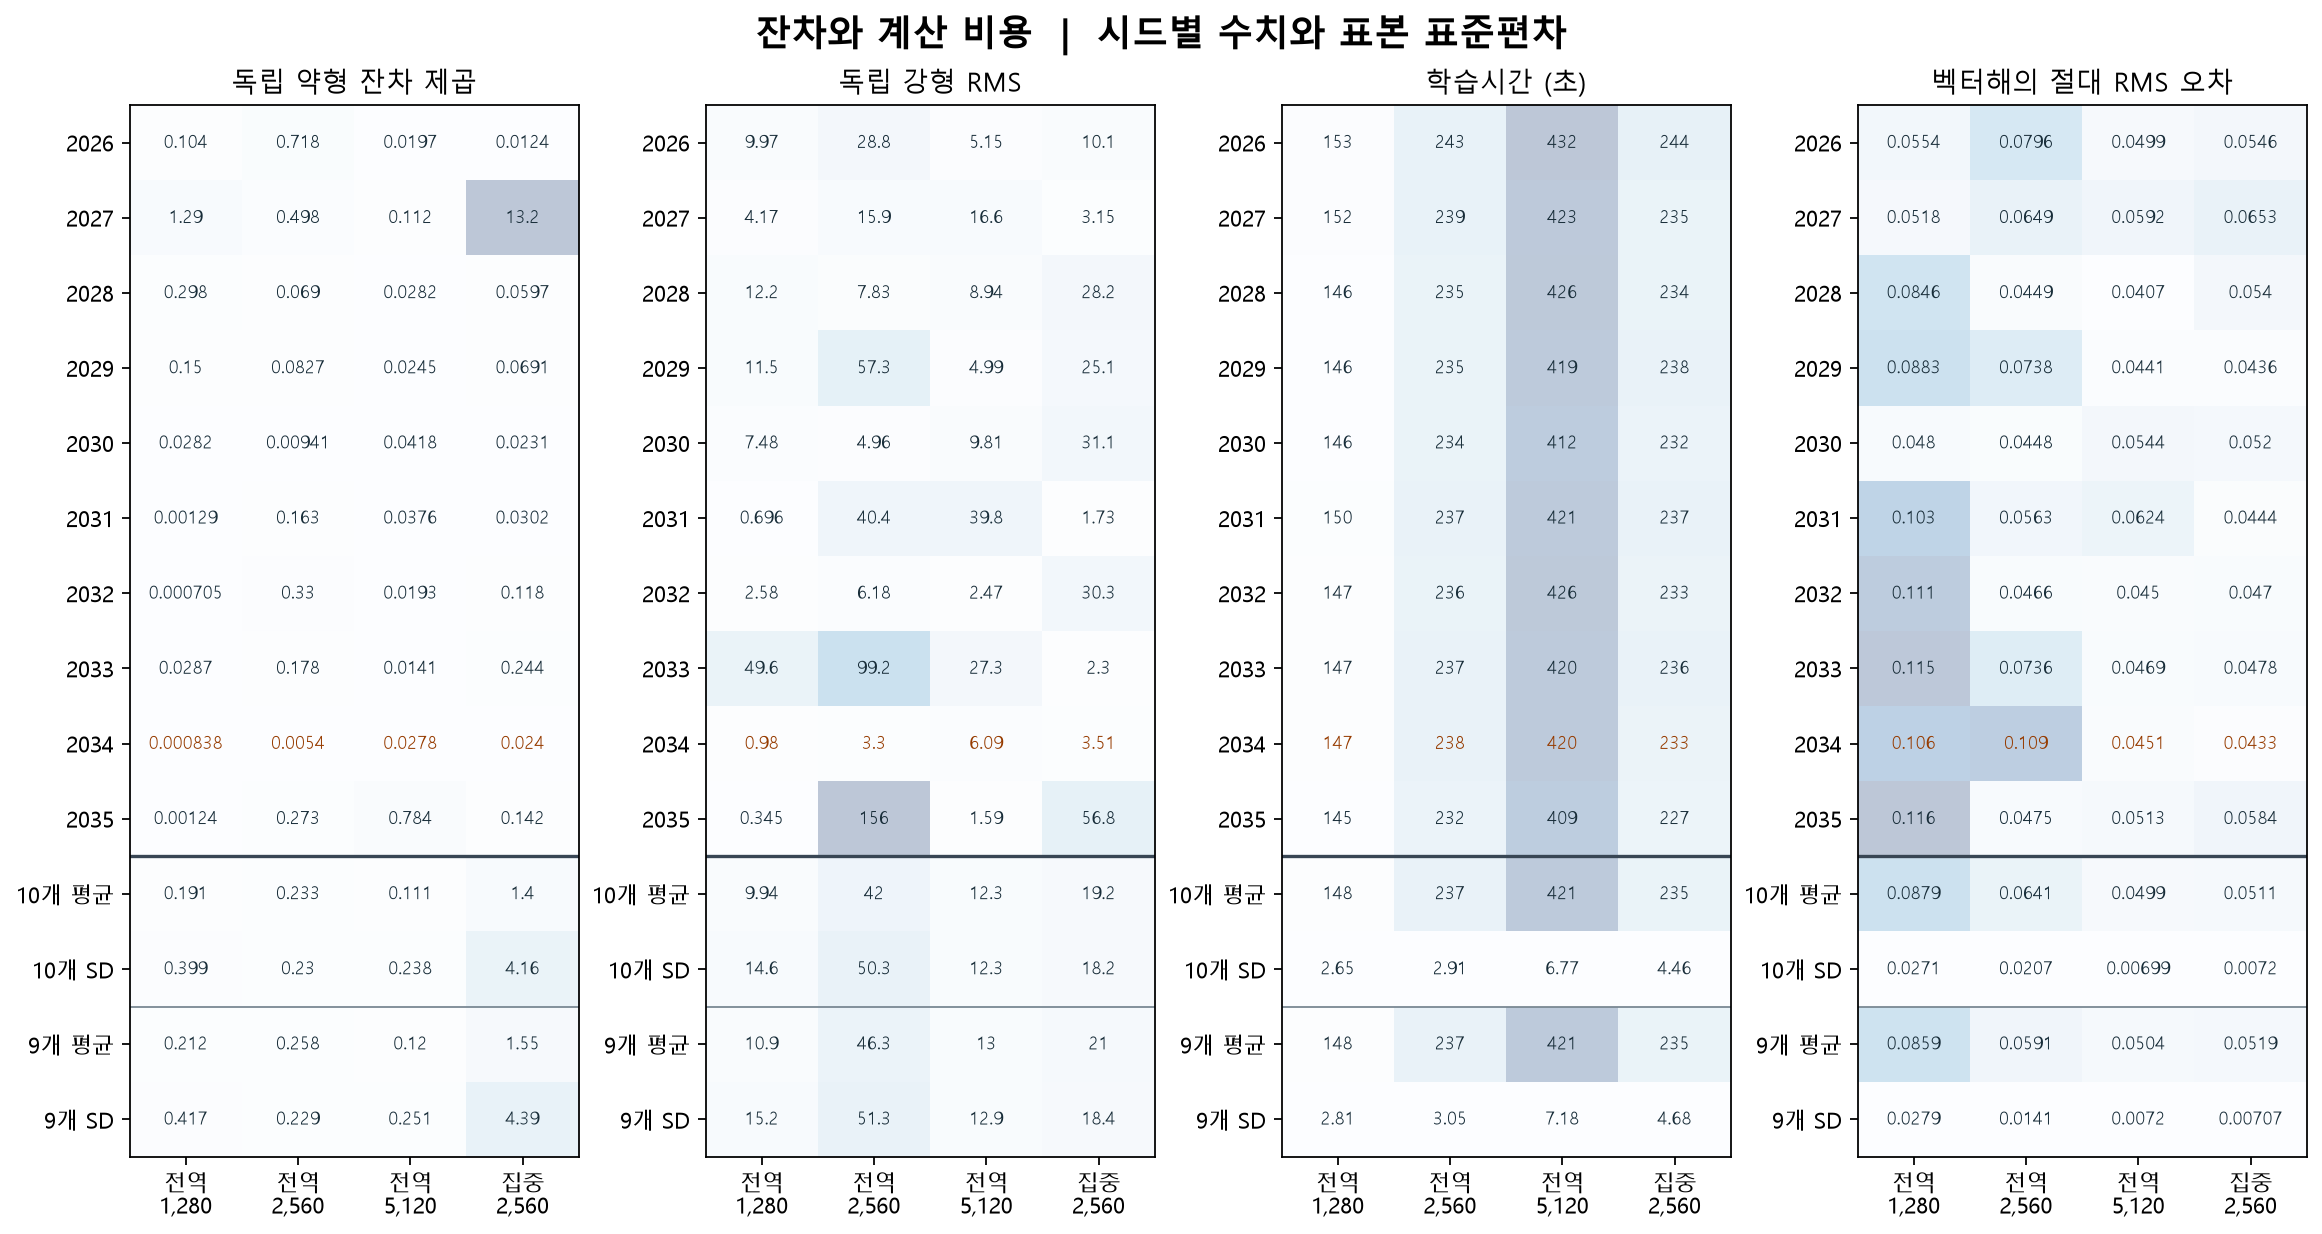

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_values_2.png'))

각 열은 한 배치다. 아래 네 줄은 평균과 표본 SD이며, —는 유일한 하향 통과를 정할 수 없어 해당 지표를 집계에서 제외한 경우다. 색 농도는 각 지표 안에서만 비교한다.

### 초기·경계 조건과 층 형상 · 시드별 결과

가는 선 하나가 같은 시드의 네 배치 결과다. 주황색 점선은 2034다. 각 배치 옆 검정 마름모와 파란 사각형은 각각 전체 10개와 2034 제외 9개의 평균이며, 세로 막대는 표본 표준편차(±1 SD)다. 아래 숫자 지도에서 개별 점의 값을 확인할 수 있다.

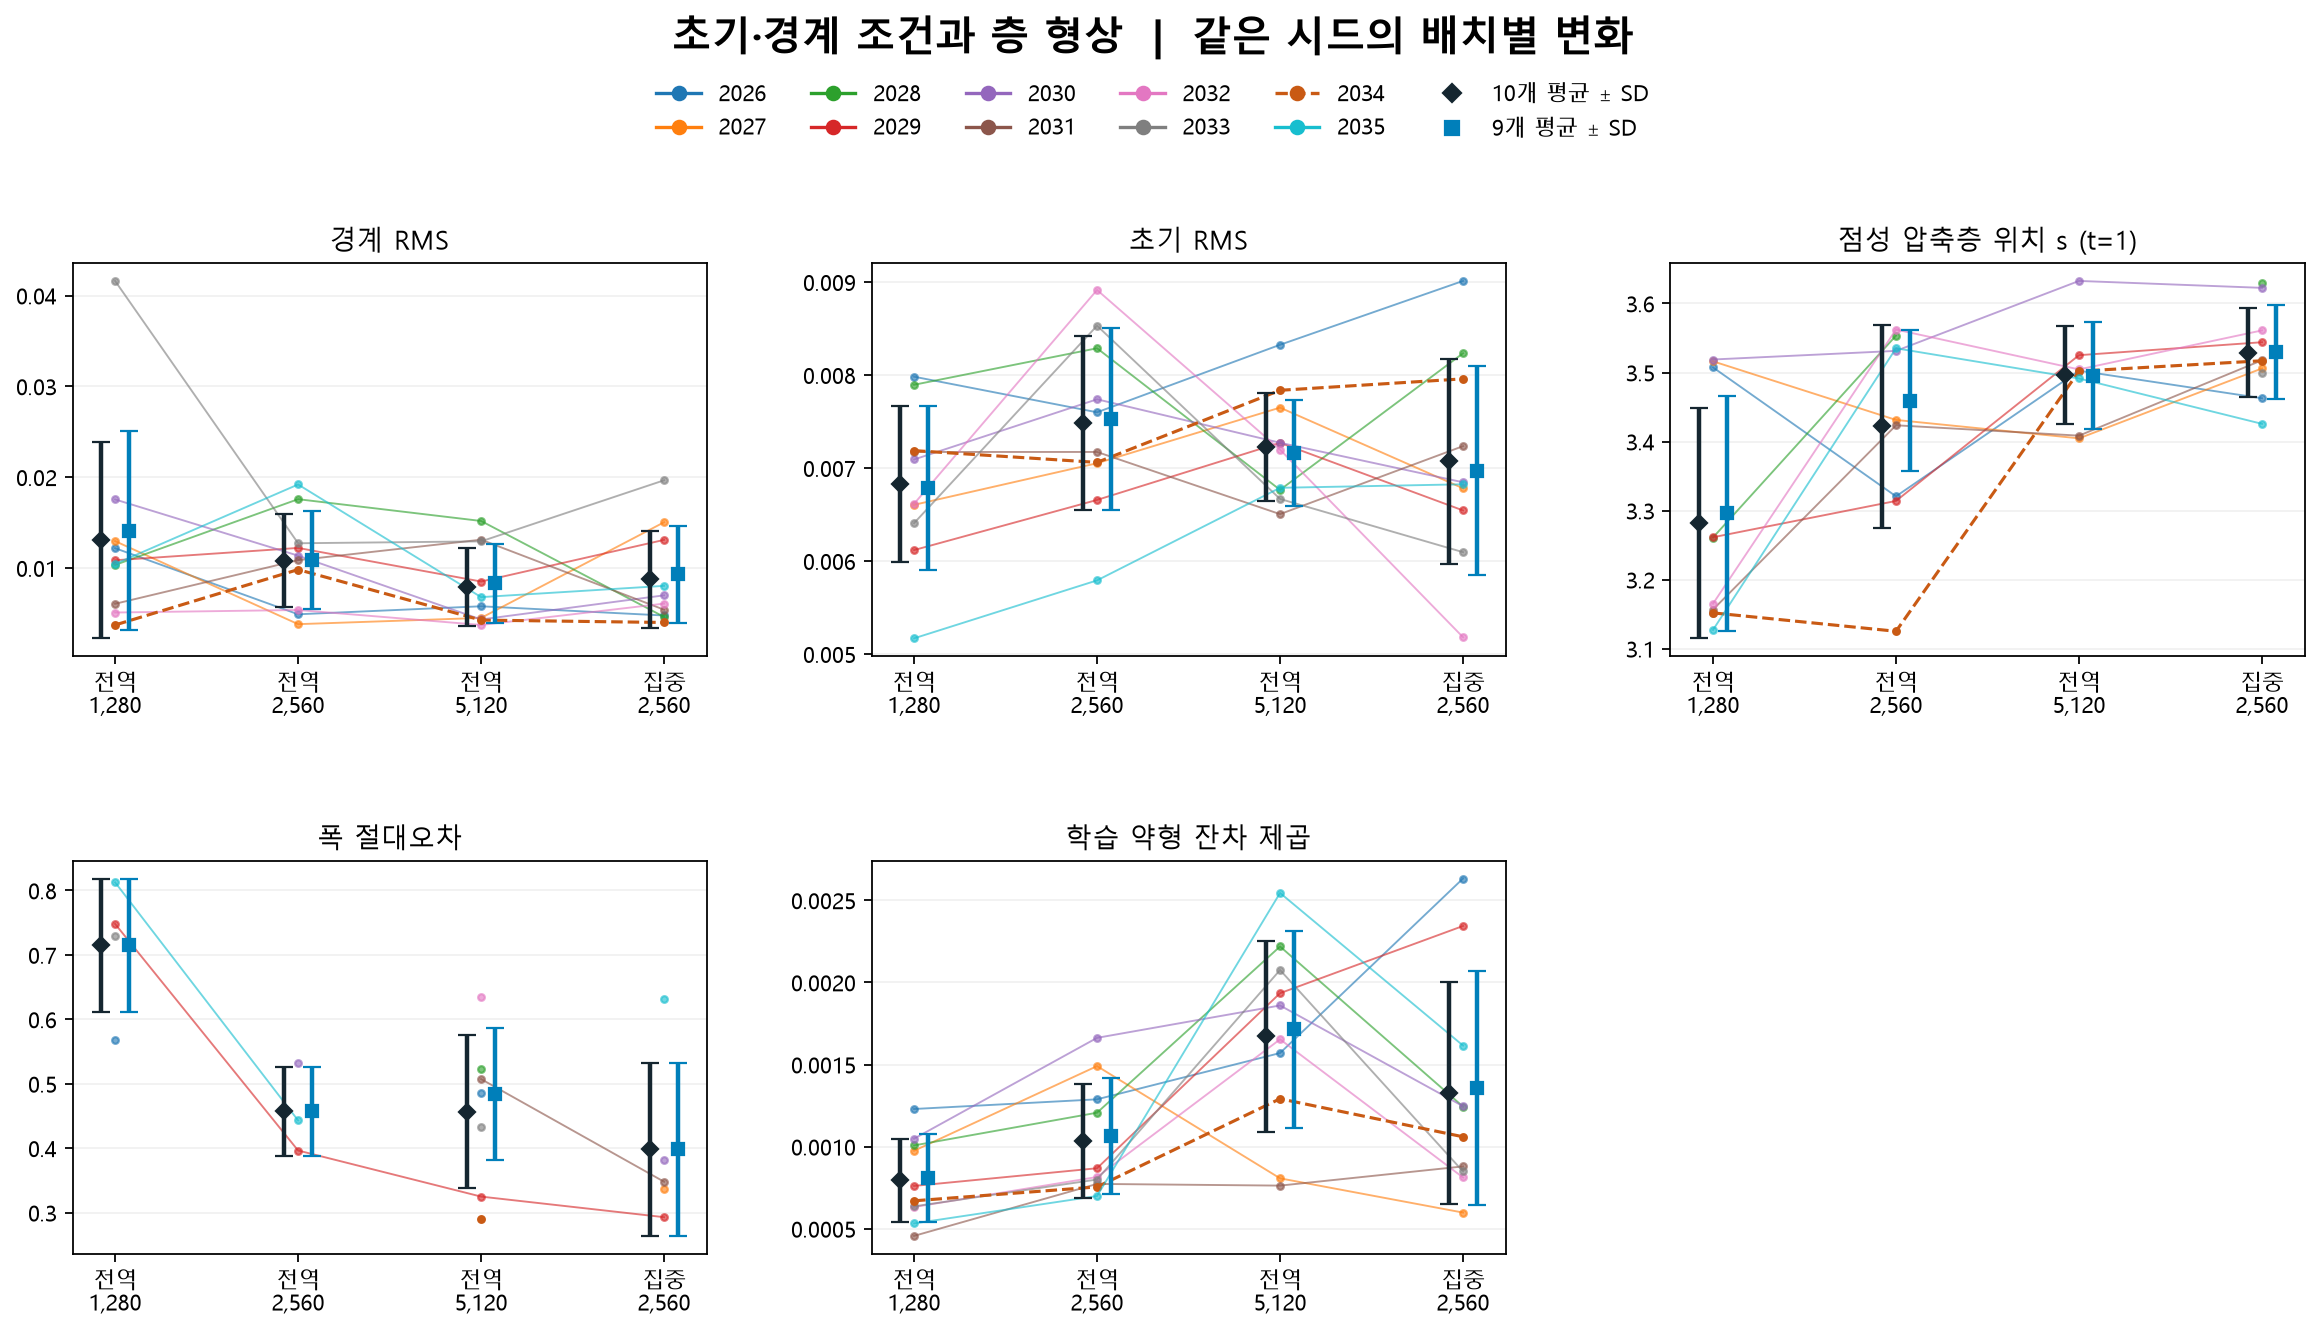

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_profiles_3.png'))

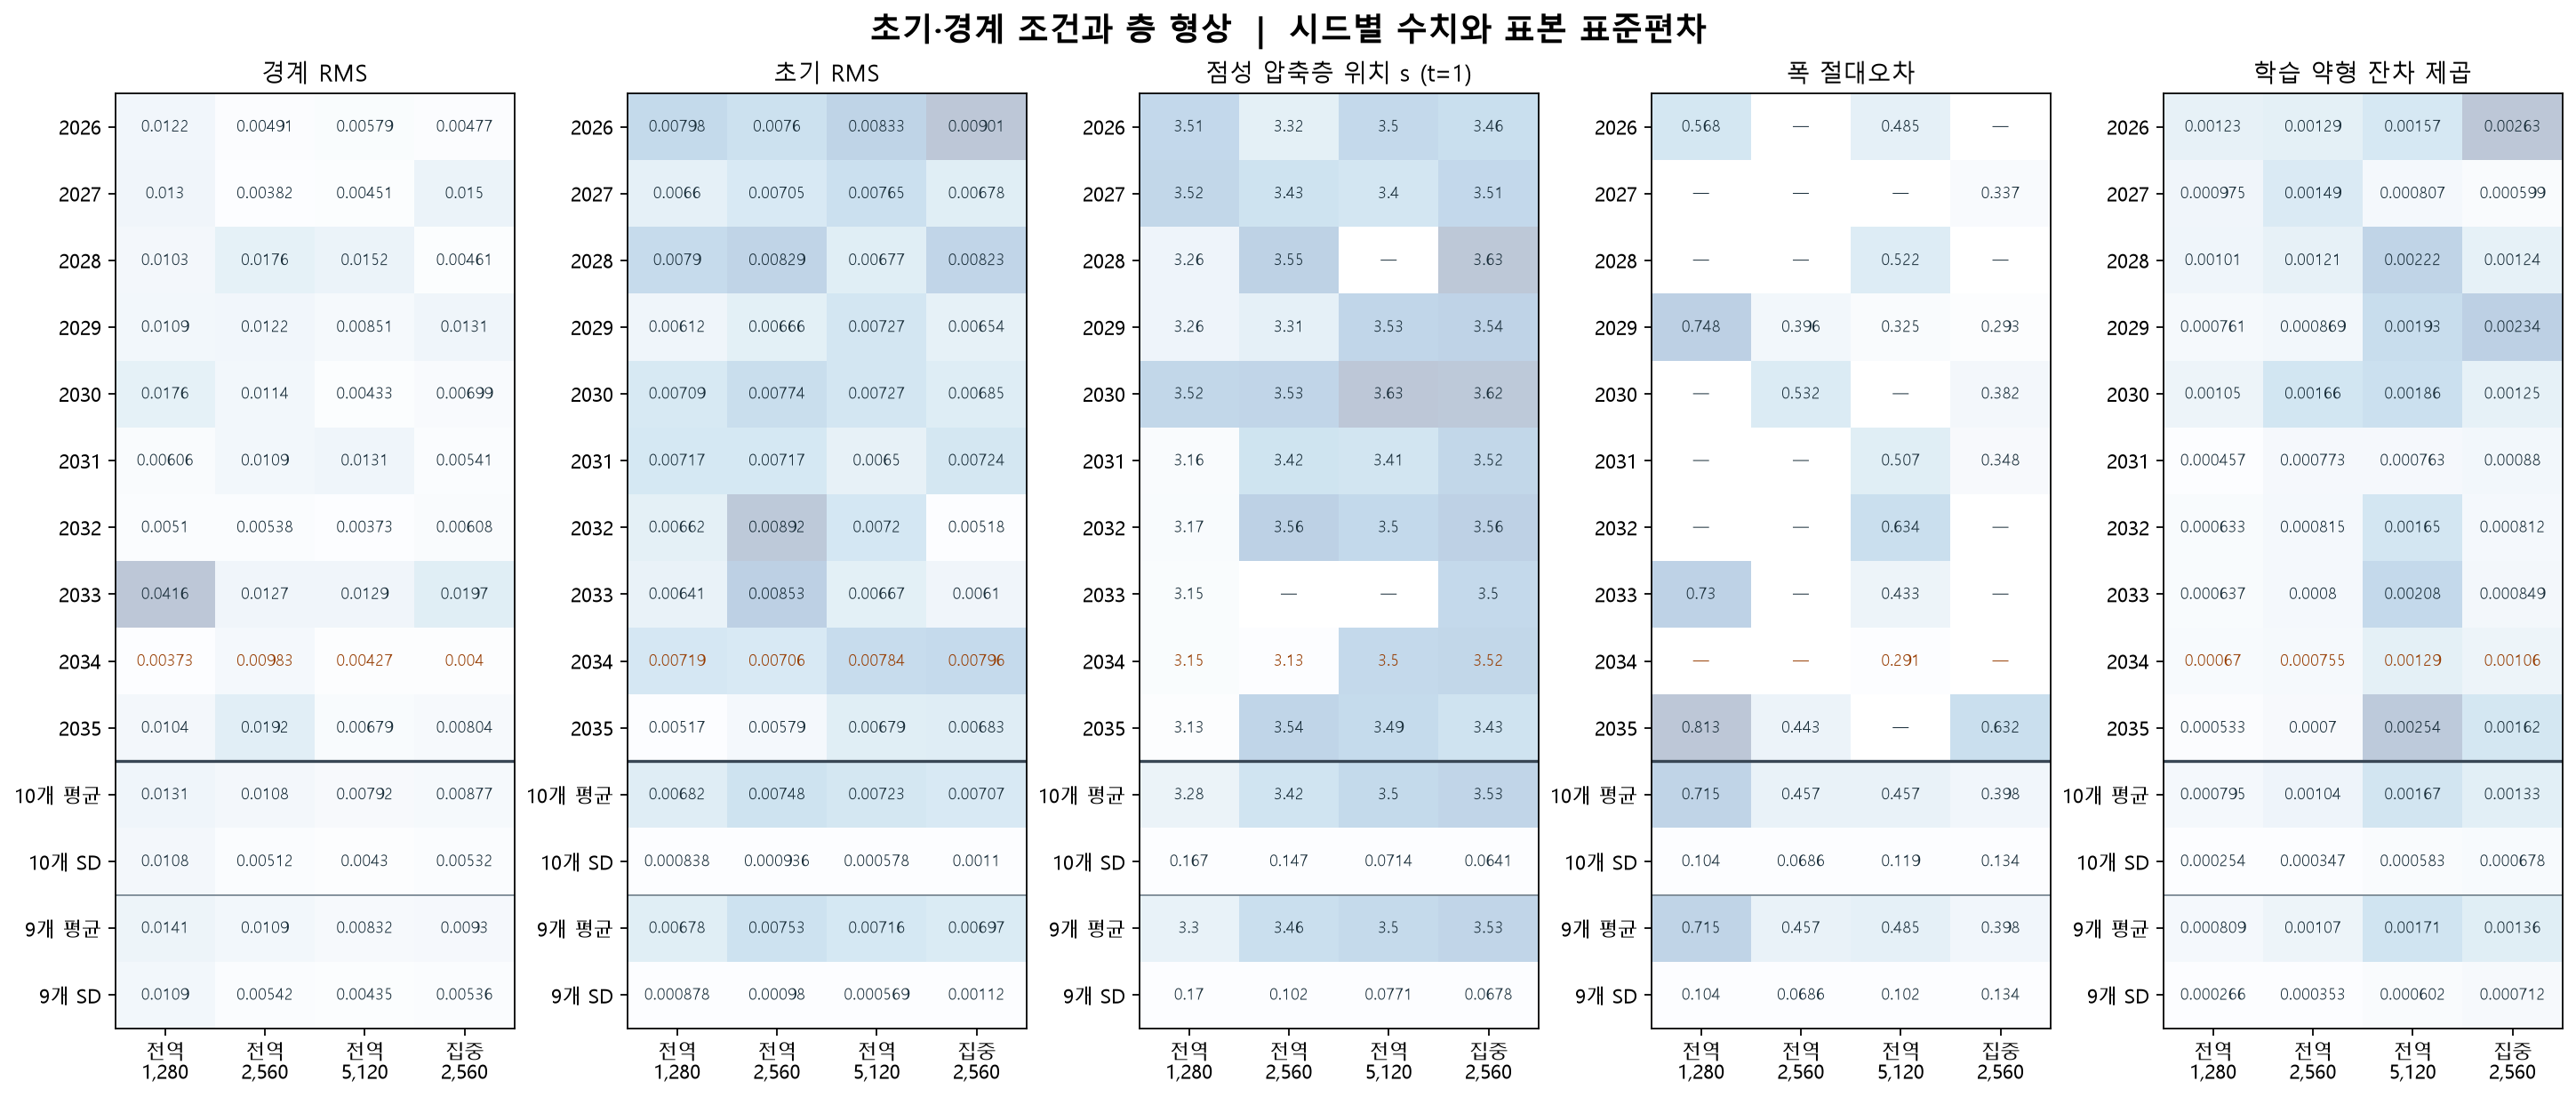

In [ ]:
from IPython.display import Image,display
display(Image(filename='replication/seed_values_3.png'))

각 열은 한 배치다. 아래 네 줄은 평균과 표본 SD이며, —는 유일한 하향 통과를 정할 수 없어 해당 지표를 집계에서 제외한 경우다. 색 농도는 각 지표 안에서만 비교한다.

### 같은 2,560점에서 집중 배치의 효과

시드별 집중−전역 차이의 평균 ± 표본 SD다. 음수는 집중 배치에서 감소를 뜻한다. 괄호는 유효 시드 수다. 상대 오차 차이 단위는 %p다.

|지표|전체 10개|2034 제외 9개|
|---|---|---|
|점성 압축층 위치 절대오차 (t=1)|-0.07539 ± 0.163 (9/10)|-0.03584 ± 0.119 (8/9)|
|상대 L2 (%)|-2.697 ± 4.98 (10/10)|-1.486 ± 3.37 (9/9)|
|상대 H1 semi (%)|1.226 ± 138 (10/10)|14.43 ± 140 (9/9)|
|벡터해의 표본 L∞ 절대오차|-0.09553 ± 0.444 (10/10)|-0.06451 ± 0.459 (9/9)|
|독립 약형 제곱|1.164 ± 4.07 (10/10)|1.291 ± 4.3 (9/9)|
|강형 PDE 잔차 RMS|-22.79 ± 45.7 (10/10)|-25.34 ± 47.7 (9/9)|
|학습 초|-1.692 ± 2.45 (10/10)|-1.364 ± 2.35 (9/9)|

### 네 배치의 집계값 · 평균과 표본 SD

<details><summary>전체 10개 · 10개 시드</summary>

|지표|전역 1280|전역 2560|전역 5120|집중 2560|
|---|---|---|---|---|
|점성 압축층 위치 절대오차 (t=1)|0.2614 ± 0.167 (10/10)|0.1278 ± 0.14 (9/10)|0.0691 ± 0.0462 (8/10)|0.0515 ± 0.0373 (10/10)|
|상대 L2 (%)|18.16 ± 5.59 (10/10)|13.25 ± 4.27 (10/10)|10.31 ± 1.44 (10/10)|10.55 ± 1.49 (10/10)|
|상대 H1 semi (%)|481.6 ± 274 (10/10)|313.5 ± 94.9 (10/10)|241.6 ± 76.8 (10/10)|314.7 ± 148 (10/10)|
|벡터해의 표본 L∞ 절대오차|2.066 ± 1.3 (10/10)|1.309 ± 0.561 (10/10)|1.008 ± 0.526 (10/10)|1.214 ± 0.901 (10/10)|
|독립 약형 제곱|0.1906 ± 0.399 (10/10)|0.2326 ± 0.23 (10/10)|0.1109 ± 0.238 (10/10)|1.397 ± 4.16 (10/10)|
|강형 PDE 잔차 RMS|9.942 ± 14.6 (10/10)|42.01 ± 50.3 (10/10)|12.27 ± 12.3 (10/10)|19.22 ± 18.2 (10/10)|
|벡터해의 절대 RMS 오차|0.0879 ± 0.0271 (10/10)|0.06412 ± 0.0207 (10/10)|0.0499 ± 0.00699 (10/10)|0.05106 ± 0.0072 (10/10)|
|점성 압축층 위치 s (t=1)|3.282 ± 0.167 (10/10)|3.422 ± 0.147 (9/10)|3.496 ± 0.0714 (8/10)|3.529 ± 0.0641 (10/10)|
|폭 절대오차|0.7147 ± 0.104 (4/10)|0.4571 ± 0.0686 (3/10)|0.4569 ± 0.119 (7/10)|0.3983 ± 0.134 (5/10)|
|경계 RMS|0.01308 ± 0.0108 (10/10)|0.01079 ± 0.00512 (10/10)|0.007916 ± 0.0043 (10/10)|0.008771 ± 0.00532 (10/10)|
|초기 RMS|0.006825 ± 0.000838 (10/10)|0.007481 ± 0.000936 (10/10)|0.007228 ± 0.000578 (10/10)|0.007072 ± 0.0011 (10/10)|
|학습 초|147.9 ± 2.65 (10/10)|236.8 ± 2.91 (10/10)|420.9 ± 6.77 (10/10)|235.1 ± 4.46 (10/10)|
|학습 약형 제곱|0.000795 ± 0.000254 (10/10)|0.001036 ± 0.000347 (10/10)|0.001672 ± 0.000583 (10/10)|0.001328 ± 0.000678 (10/10)|

</details>

<details><summary>2034 제외 9개 · 9개 시드</summary>

|지표|전역 1280|전역 2560|전역 5120|집중 2560|
|---|---|---|---|---|
|점성 압축층 위치 절대오차 (t=1)|0.247 ± 0.17 (9/9)|0.09153 ± 0.0945 (8/9)|0.07308 ± 0.0484 (7/9)|0.05432 ± 0.0384 (9/9)|
|상대 L2 (%)|17.75 ± 5.77 (9/9)|12.21 ± 2.91 (9/9)|10.42 ± 1.49 (9/9)|10.73 ± 1.46 (9/9)|
|상대 H1 semi (%)|494.7 ± 287 (9/9)|315.8 ± 100 (9/9)|248 ± 78.6 (9/9)|330.2 ± 148 (9/9)|
|벡터해의 표본 L∞ 절대오차|2.185 ± 1.32 (9/9)|1.35 ± 0.579 (9/9)|1.02 ± 0.556 (9/9)|1.285 ± 0.925 (9/9)|
|독립 약형 제곱|0.2117 ± 0.417 (9/9)|0.2578 ± 0.229 (9/9)|0.1202 ± 0.251 (9/9)|1.549 ± 4.39 (9/9)|
|강형 PDE 잔차 RMS|10.94 ± 15.2 (9/9)|46.31 ± 51.3 (9/9)|12.96 ± 12.9 (9/9)|20.97 ± 18.4 (9/9)|
|벡터해의 절대 RMS 오차|0.08592 ± 0.0279 (9/9)|0.05912 ± 0.0141 (9/9)|0.05043 ± 0.0072 (9/9)|0.05192 ± 0.00707 (9/9)|
|점성 압축층 위치 s (t=1)|3.296 ± 0.17 (9/9)|3.459 ± 0.102 (8/9)|3.496 ± 0.0771 (7/9)|3.53 ± 0.0678 (9/9)|
|폭 절대오차|0.7147 ± 0.104 (4/9)|0.4571 ± 0.0686 (3/9)|0.4845 ± 0.102 (6/9)|0.3983 ± 0.134 (5/9)|
|경계 RMS|0.01412 ± 0.0109 (9/9)|0.01089 ± 0.00542 (9/9)|0.008322 ± 0.00435 (9/9)|0.0093 ± 0.00536 (9/9)|
|초기 RMS|0.006784 ± 0.000878 (9/9)|0.007528 ± 0.00098 (9/9)|0.007161 ± 0.000569 (9/9)|0.006973 ± 0.00112 (9/9)|
|학습 초|148 ± 2.81 (9/9)|236.7 ± 3.05 (9/9)|420.9 ± 7.18 (9/9)|235.3 ± 4.68 (9/9)|
|학습 약형 제곱|0.0008089 ± 0.000266 (9/9)|0.001067 ± 0.000353 (9/9)|0.001714 ± 0.000602 (9/9)|0.001358 ± 0.000712 (9/9)|

</details>

### 결과 해석

누적 10개에서 어느 시드든 하나씩 제외한 열 가지 경우도 확인했다. 평균 위치 차이 범위는 -0.0985 ~ -0.0358였다. 모든 제외 선택에서 집중 배치의 평균 위치 오차가 작았다.

**점성 압축층 위치 절대오차 (t=1)**의 집중−전역 평균 차이는 전체 10개에서 -0.07539, 2034 제외 후 -0.03584였다.

**상대 H1 semi (%)**의 집중−전역 평균 차이는 전체 10개에서 +1.226, 2034 제외 후 +14.43였다.

**상대 L2 (%)**의 집중−전역 평균 차이는 전체 10개에서 -2.697, 2034 제외 후 -1.486였다.

집중 배치의 위치 개선폭은 시드 제외 후 절반가량으로 줄었다. 위치를 판정할 수 있는 짝은 각각 9쌍과 8쌍이다. 같은 2,560점에서 L2 개선 방향도 유지됐지만, 기울기 오차의 평균 차이는 +1.23 → +14.43%p로 커졌다. 두 집합 모두에서 집중 배치는 평균 강형 RMS를 줄이고 독립 약형 잔차 제곱을 키웠다. 약형 지표의 큰 SD도 함께 읽어야 한다.

전역 5,120점은 두 집합에서 평균 L2·H1·최대오차가 가장 작았다. 집중 2,560점은 약 235초로 전역 5,120점(약 421초)에 가까운 평균 L2를 얻었으나 기울기 오차는 더 컸다. P3로 층 위치를 미리 구하는 비용은 이 학습시간에서 제외했다.

제외된 시드도 정상적으로 완료된 실행이다. 제외 후 SD는 선택에 영향을 받는다. 위치 오차를 기준으로 선택했으므로 잔차나 기울기에서 편차가 가장 큰 시드는 다를 수 있다.